# Panel run explorer: the instrument and the annotations

This notebook lets you **look at everything one annotation run produced**, without reading or writing any code:
the codebooks and the prompt exactly as the model received them, what the model wrote down for one video
(who spoke, what they asked, how it was answered, who decided what), how far two independent passes of the
model agree with each other, where human review stands, and what the run cost.

**How to use this notebook**

1. Pick the kernel: choose the project's `.venv` Python (in Jupyter: *Kernel → Change kernel*; in VS Code: *Select Kernel*).
2. Edit the **configuration cell** just below. It is the only cell you need to change.
3. Run everything: *Kernel → Restart & Run All*. It takes well under a minute.

**What it does not do.** It makes **no model calls** and costs nothing to run. It **never changes annotation
files**: it only reads them. With `EXPORT = False` (the default) it writes nothing at all. The saved outputs you
see when you first open the file come from a real run of this notebook on the run named in the configuration cell.

**What the results mean.** Everything shown here was written by a model unless section E says a human has
reviewed it. Agreement between two passes of the same model (section D) shows the instrument is *stable*; it
does not show the codes are *right*.

Sections: **A** run overview · **B** the instrument as the model saw it · **C** one video's record ·
**D** agreement between the two passes · **E** human review · **F** Stage A ranking · **G** comparison with the
earlier pipeline · **H** optional export

In [1]:
# ===== CONFIGURATION — the only cell you need to edit. Then: Kernel > Restart & Run All =====

RUN_NAME = "full-corpus-100"   # the run to look at: a folder name under runs/ (or the full path of a run folder)
# VIDEO_IDS: the videos this notebook looks at. Three ways to say which:
#   the name of a selection file, inside the run folder or given relative to it (or as a full path):
#     "selection_all100.json" is all 100 annotated videos (the same 100 pitches the earlier
#     v3-dev8 run annotated, listed with their development videos; this run re-annotated them with release v3-dev9);
#   a list of video ids, e.g. ["st_8a6fd25840", "st_ec62d6e492"];
#   None = every video of the run that has at least one annotation pass.
# Five of the videos are the development (pilot) videos on which the instrument was first written: st_38f8bf18e0,
# st_8642720802, st_aebb7e3764, st_d218d68cff, st_ea076612ce. The selection file names them under
# "pilot_development_videos".
VIDEO_IDS = "selection_all100.json"
VIDEO_ID = "st_8a6fd25840"          # which video sections B-D show: an id from the table in section A.
                                    #   None = the first of VIDEO_IDS
PASS = "primary"                    # which annotation of that video to show:
                                    #   "primary"   = the model's first pass. It is what the analysis reads, except where it
                                    #                 fails the automatic checks and the second pass fails fewer of them:
                                    #                 the column "Analysis reads" in section A says which, per video
                                    #   "replicate" = the model's second, independent pass
                                    #   "reviewed"  = the human-corrected record, when one exists
SHOW_FULL_PROMPT = True            # False shows the start and end of the prompt; True prints all of it (long)
FREQUENCY_PASS = "analysis"           # which annotation section A2 counts values in:
                                    #   "analysis"  = for each video the pass the analysis reads (recommended)
                                    #   "primary" or "replicate" = that pass for every video
INPUT_USD_PER_M = 2.0               # assumed price in US dollars per million INPUT tokens (for the cost column)
OUTPUT_USD_PER_M = 12.0             # assumed price per million OUTPUT and THINKING tokens
EXPORT = False                      # False writes nothing. True also saves the tables as CSV files
                                    #   under runs/<run>/analysis/explorer/

In [2]:
# Setup: finds the project folder and loads the selected run. Nothing to edit here.
import sys
from pathlib import Path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "analysis" / "panel_explorer.py").exists())
sys.path.insert(0, str(REPO))
from IPython.display import display
from analysis import panel_explorer as px

RUN = px.resolve_run(RUN_NAME)
VIDEO_IDS = px.resolve_video_ids(RUN, VIDEO_IDS)      # a selection file name becomes its list of video ids
VIDEO = px.pick_video(RUN, VIDEO_ID, VIDEO_IDS)
result, shown_pass, pass_note = px.load_pass(VIDEO, PASS)
inst = px.instrument(VIDEO)
print(f"Run: {RUN.name}\nSelected video: {VIDEO.name}\n{pass_note}")


Run: full-corpus-100
Selected video: st_8a6fd25840
Showing the primary pass of st_8a6fd25840.


## A. Run overview

**What this shows.** One row per video in the run (those named in `VIDEO_IDS`, or all of them when it is `None`): what the venture is, which instrument release annotated it,
which passes exist (the model annotates each video twice, independently: `primary` and `replicate`; `reviewed`
appears once a human has corrected the primary pass), which of them the analysis reads (*Analysis reads*: the
human-corrected record when there is one; otherwise the primary pass, or the replicate pass when the primary
fails the automatic checks and the replicate fails fewer of them), and how many problems the automatic checks found in each
pass, written as `errors / flags`. An *error* is a rule a record must meet (for example, an investor who speaks
in an exchange must be listed in it). A *flag* is something worth a look that is not necessarily wrong (for
example, a question nobody answered). The last columns count model calls and tokens and turn them into an
estimated cost using the prices in the configuration cell.

**What it does not establish.** Zero errors means a record is well-formed, not that it is accurate. The cost is
an estimate from the call log at assumed prices, not an invoice.

In [3]:
overview = px.run_overview(RUN, INPUT_USD_PER_M, OUTPUT_USD_PER_M, VIDEO_IDS)
display(overview)
print(px.overview_summary(overview))

,Video,Venture,Release,Length,Passes,Analysis reads,primary: errors / flags,replicate: errors / flags,Human-reviewed,Model calls,Failed calls,Input tokens,Output tokens,Thinking tokens,Estimated cost (USD)
0,st_026c012f68,Portable coolers,v3-dev9,9:57,"primary, replicate",primary,0 / 18,0 / 11,no,2,0,128726,37851,39059,1.18
1,st_02f25e2b0a,cookies and brownies,v3-dev9,9:23,"primary, replicate",primary,0 / 7,1 / 22,no,2,0,122540,24890,35635,0.97
2,st_03c7703a04,portable mini-keg,v3-dev9,9:18,"primary, replicate",primary,0 / 22,2 / 15,no,2,0,121630,32883,44674,1.17
3,st_04fd2fd01d,cookies,v3-dev9,9:25,"primary, replicate",primary,0 / 12,0 / 12,no,2,0,122904,26687,30841,0.94
4,st_05bb42aa6d,custom gift boxes,v3-dev9,11:57,"primary, replicate",replicate,9 / 36,0 / 8,no,2,0,150562,50701,50273,1.51
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,st_fb39374b09,extreme cold weather apparel,v3-dev9,10:25,"primary, replicate",primary,0 / 11,0 / 6,no,2,0,133824,36106,40406,1.19
96,st_fb94ba9b86,small lockable container,v3-dev9,7:14,"primary, replicate",primary,0 / 8,0 / 8,no,2,0,99054,26778,31459,0.90
97,st_fd5a8ee737,toilet deodorizer tablets,v3-dev9,8:01,"primary, replicate",replicate,1 / 13,0 / 16,no,2,0,107616,20052,36288,0.89
98,st_fe22601532,Kimchi and DIY kits,v3-dev9,10:11,"primary, replicate",primary,0 / 5,0 / 4,no,2,0,131276,28447,33235,1.00


100 videos; instrument release v3-dev9; 0 human-reviewed; 202 model calls; estimated cost $111.83 at the prices in the configuration cell. The analysis reads: the primary pass of 79, the replicate pass of 21 (the replicate only where the primary pass has validation errors and the replicate has fewer).


### A2. How often each value of each code is used

**What this shows.** For every code in the three codebooks, how often each of its allowed values was used
across the videos of `VIDEO_IDS`. The table first: per code, the most common value and its share, the values
that were **never used**, the **rare** values (used for under 1% of units), and how often the code was left
missing. Then one chart per group of codes with the same kind of values. In the charts every allowed value
has a bar, so a value that was never applied is visible ("never used"); a **dark blue** bar is a dominant
value (80% or more of units), an **orange** bar a rare one, and **hatched grey** bars are units left without
a value, with the reason the model gave.

**Unit and denominator.** Each chart title says what one unit is and how many there are: turns for what a
turn does; question or answer turns for the question and answer codes; substantive exchanges for topics;
decisions; and pitches for Stage A and the
venture codes. Shares are of all units on which the code was recorded, missing ones included.
`FREQUENCY_PASS` in the configuration cell chooses whose annotation is counted.

**What it does not show.** Whether the values are right: these are the model's codes, not checked by a
person. A value that is never or rarely used is either genuinely rare in this footage or a category the model
does not apply; a dominant value may mean the code barely varies and will carry little information in the
models. `NONE` ("no value applies") is shown but is never listed as an unused value.


In [4]:
counts = px.code_value_counts(RUN, inst.books, VIDEO_IDS, FREQUENCY_PASS)
print(f"Counted over {len(px.video_dirs(RUN, VIDEO_IDS))} videos, pass: {FREQUENCY_PASS}.")
px.show(px.value_usage_summary(counts), "No code was counted (no video has the chosen pass).", whole=True)

Counted over 100 videos, pass: analysis.


Code,Name,Counted units,Most common value,Its share,Dominant (80% or more),Values never used,Rare values (under 1%),Left missing (share),Values outside the codebook
TURN-FUNC,Turn function,6730 turns,answer,0.25,False,,"hostile, repair",0.00,
PR-CONCEPT,Question concept,1516 question turns,sales,0.18,False,,"vision, safety_security, liability, customer_retention, NONE",0.00,
RS-CONCEPT,Answer concept,1668 answer turns,sales,0.18,False,,"safety_security, liability, customer_retention",0.00,
EX-TOPIC,Exchange topic,870 substantive exchanges,execution,0.17,False,,"safety_security, liability, customer_retention",0.00,
EX-KIND,Exchange kind,1192 exchanges,substantive,0.73,False,,,0.00,
DEC-KIND,Decision kind,746 decisions,exit,0.50,False,,,0.00,
RS-RESP,Answer directness,1668 answer turns,addresses,0.91,True,,NONE,0.00,
RS-EVID,Checkable support,1668 answer turns,true,0.53,False,,,0.00,
RS-UNCERT,Admitted uncertainty or concession,1668 answer turns,false,0.96,True,,,0.00,
PR-SEV,Question severity,1516 question turns,1,0.79,False,,,0.00,


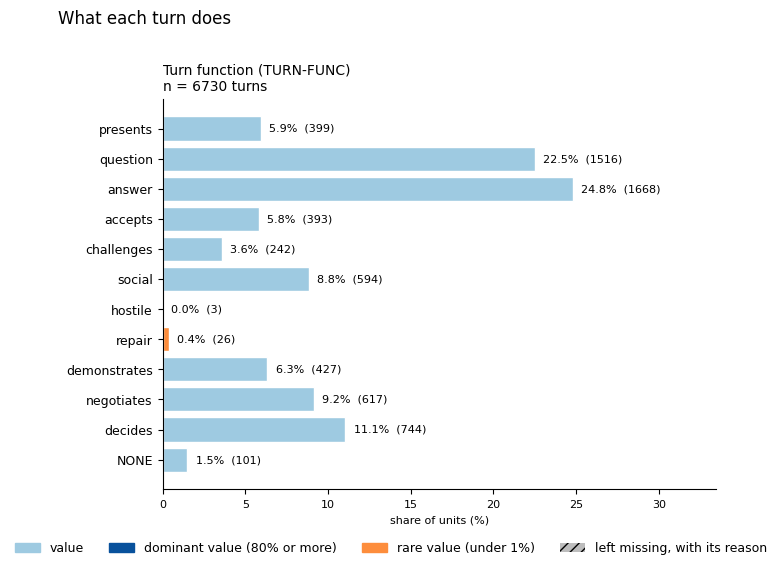

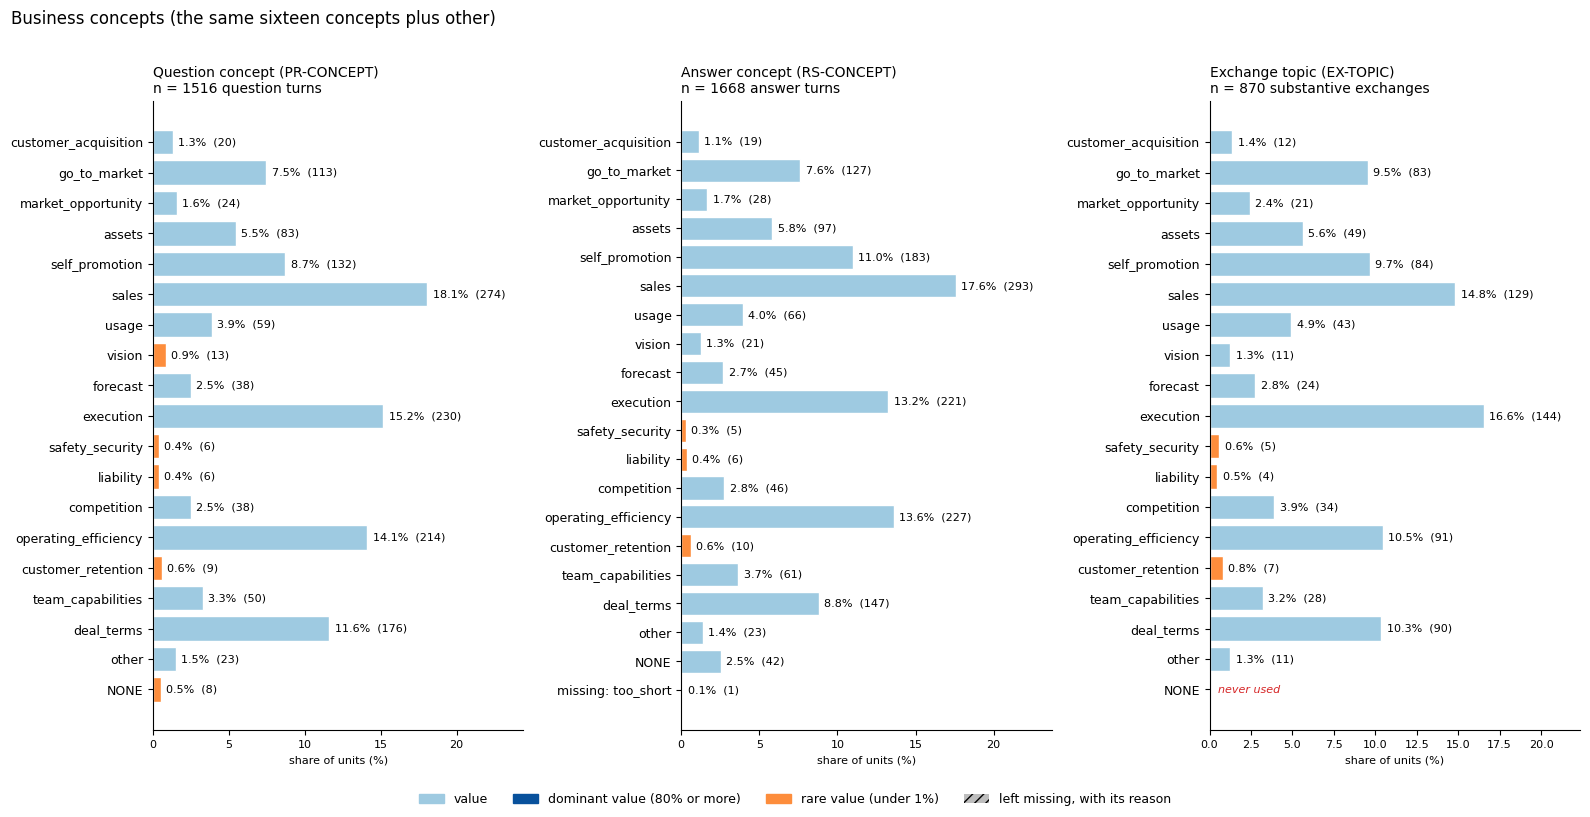

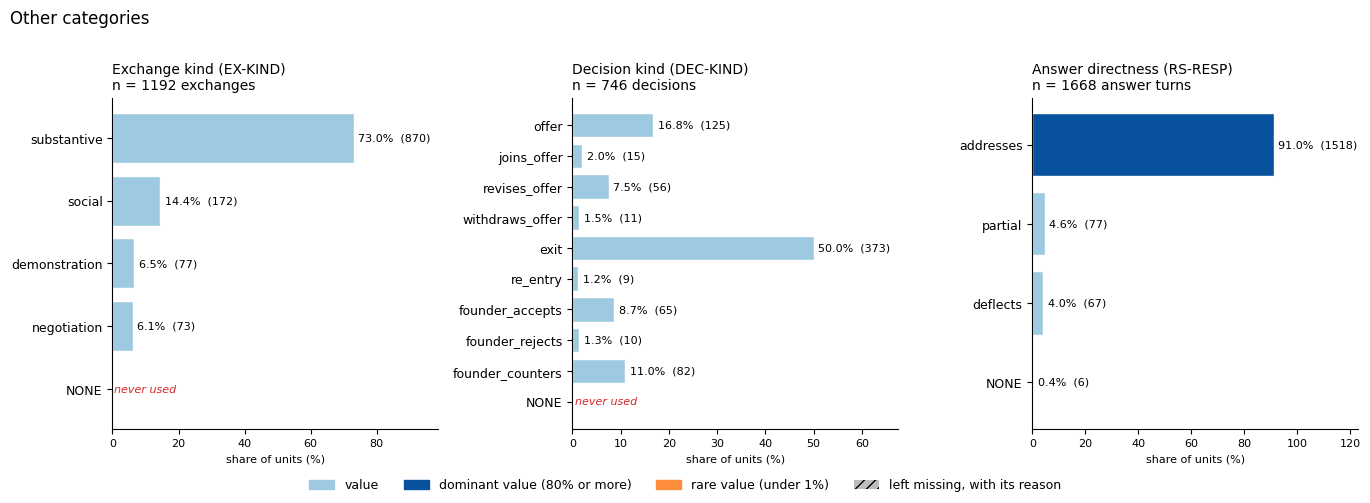

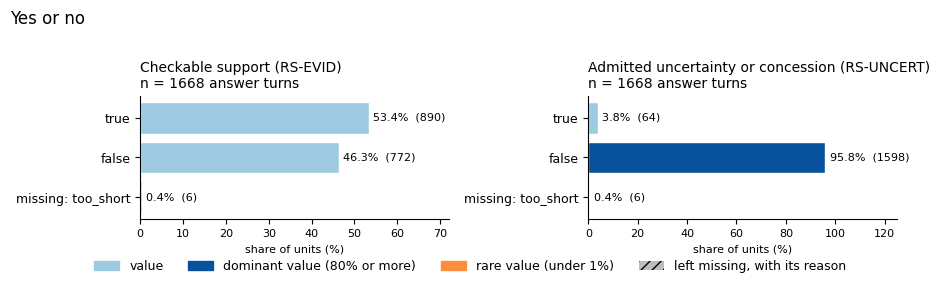

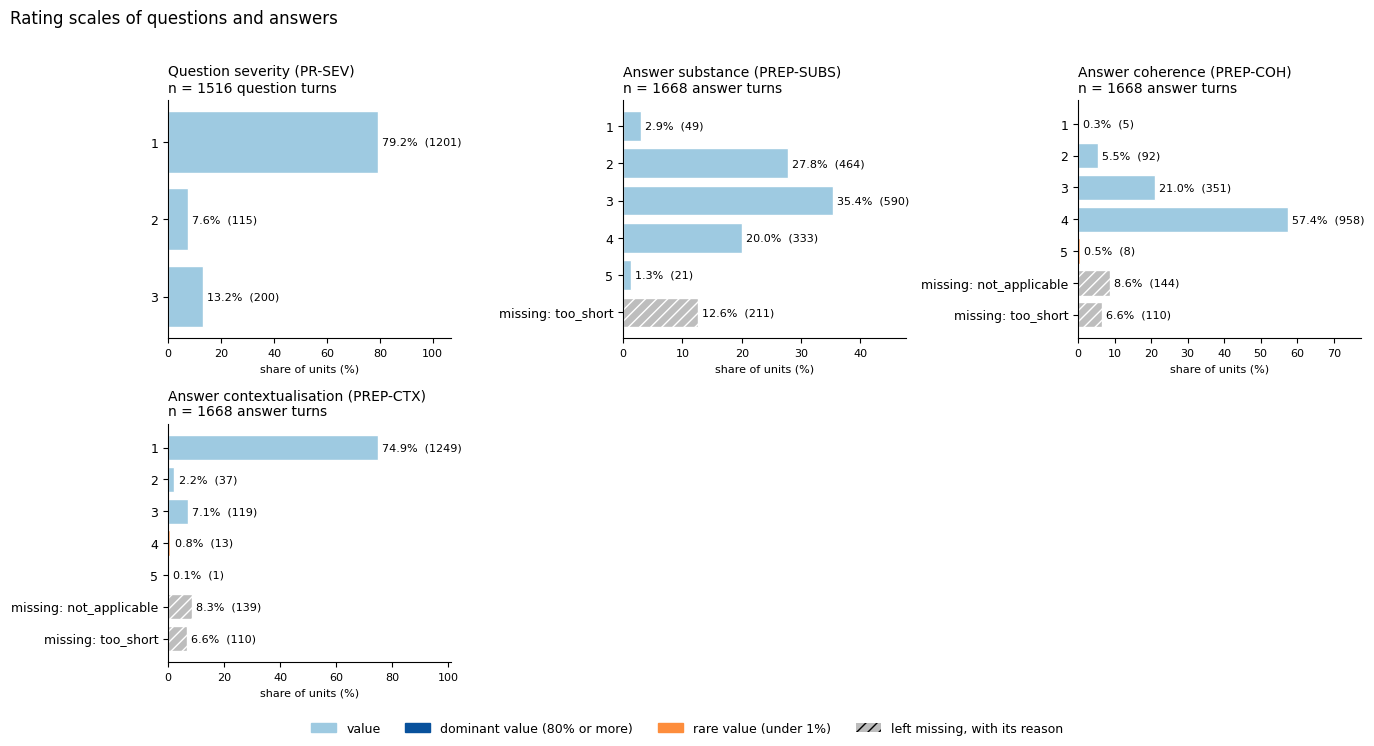

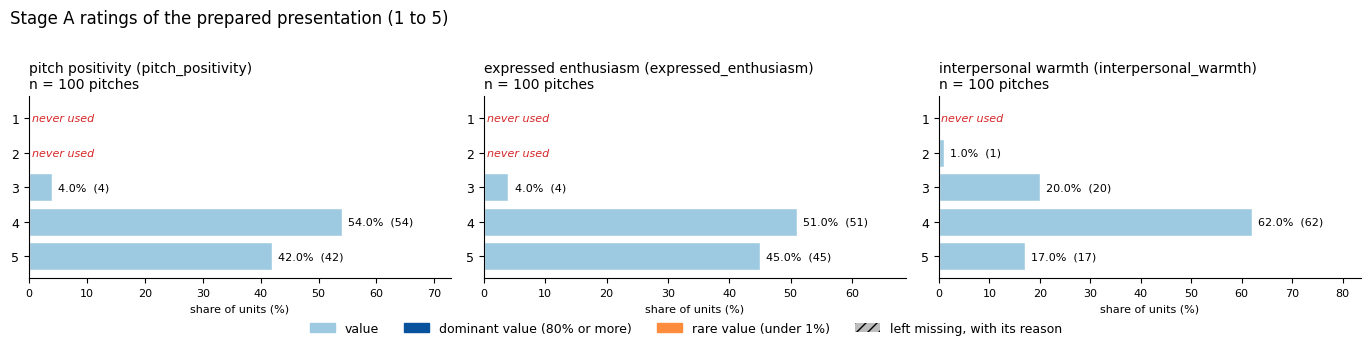

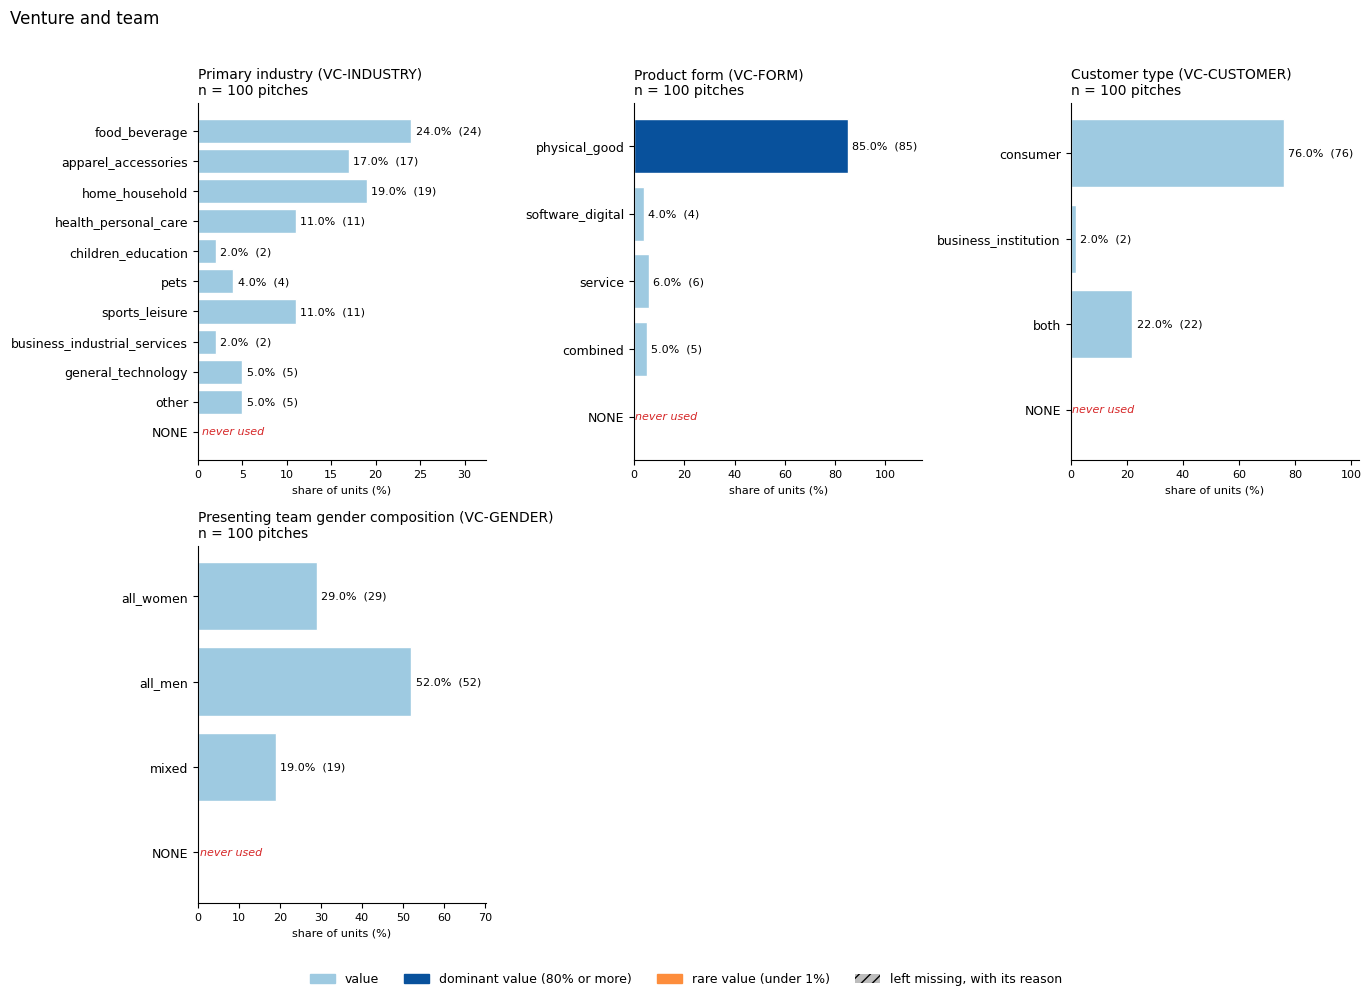

In [5]:
import matplotlib.pyplot as plt
for group, title, _ in px.VALUE_GROUPS:
    fig = px.value_frequency_figure(counts, group, title)
    if fig is None:
        print(f"{title}: nothing counted.")
    else:
        plt.show()

## B. The instrument as the model saw it

**What this shows.** The three codebooks and the prompt that were actually sent to the model for the selected
video. They are read from the copy the run saved in that video's own `bundle/` folder at the time it ran,
**never from today's codebooks**, so what you read here is what the model read, even if the codebooks have been
edited since. The first lines say whether the saved copy still equals the current ("live") release, file by file.

**What it does not establish.** That the model followed the instructions. That is what sections C to E are for.

In [6]:
print(px.instrument_note(inst))
px.show(inst.differences, "This video kept no bundle folder, so there is nothing to compare with the live release.")

Read from this video's own bundle folder (release v3-dev9). Every bundle file is identical to the live release (v3-dev9).


,File,In the live release,Same content
0,current_instrument.yaml,yes,yes
1,panel_full.j2,yes,yes
2,stage_a_perceived_delivery.j2,yes,yes
3,stage_a_perceived_delivery.md,yes,yes
4,stage_a_perceived_delivery.yaml,yes,yes
5,stage_a_perceived_delivery_protocol.md,yes,yes
6,stage_b_panel.md,yes,yes
7,stage_b_panel.yaml,yes,yes
8,venture_context.md,yes,yes
9,venture_context.yaml,yes,yes


### B1. The panel codebook (Stage B)

These are the codes the model applies to the questioning that follows the prepared presentation: what kind of
turn each utterance is, what an investor's question is about and how hard it presses, how the founder's answer
responds, how the prepared presentation is rated, and what each investor decides. *Applies to* says what one
coded unit is (a turn, an exchange, a decision). *Use when* and *Do not use when* are the inclusion and
exclusion rules. The table scrolls.

In [7]:
display(px.wide(px.codebook_table(inst.books.panel)))

Code,Name,Section,Applies to,Type,Allowed values or scale,Definition,Use when,Do not use when
TURN-FUNC,Turn function,"0. Turn, exchange and decision types",turn,categorical,"one of: presents, question, answer, accepts, challenges, social, hostile, repair, demonstrates, negotiates, decides, NONE","What the speaker does in this turn. PRESENTS: a founder delivers the prepared presentation. QUESTION: an investor requests information, explanation or substantiation about the product, the venture or the founders, or puts a claim to the founder in a way that calls for a reply. ANSWER: a founder responds to a question or to a challenge. ACCEPTS: an investor explicitly shows acceptance of what they heard — acknowledges understanding, endorses or positively assesses an answer or claim, says a concern is settled, or states liking, interest or intent short of a concrete offer. CHALLENGES: an investor asserts disagreement, doubt or a competing fact without inviting a reply. SOCIAL: a joke, compliment, tease or expression of goodwill directed at a person, or the return of one (shared laughter, a joined joke). HOSTILE: contempt, mockery, insult or dismissal of a person rather than a claim. REPAIR: a founder, after pushback or confusion, gives a materially different explanation or a revised claim; marks their own earlier statement as unclear, incomplete or wrong; hands the answer to a co-founder; steps in to fix a co-founder's answer; or contradicts a co-founder's earlier statement. DEMONSTRATES: talk that is part of showing, handing out, tasting or trying the product, by anyone. NEGOTIATES: talk about the terms of an offer that is not itself a decision. DECIDES: the turn in which a decision is spoken, together with the reasons the speaker gives for it in the same stretch of speech. NONE: a remark with none of these functions (logistics, an aside, a filler comment).","Give every turn exactly one function: the main thing the speaker does. When a speaker clearly does two different things in one stretch of speech (answers, then makes an offer; reacts, then asks a new question), split it into two consecutive turns by the same speaker. The one exception is a decision: an investor's statement that they are out or are making an offer, with the reasons given alongside it, is one decides turn and is never split into a challenge or an accepts turn plus a decision. A remark is a question only when it asks for information about the product, the venture or the founders; a comment, an exclamation or a joke phrased as a question is not. A founder's reply is an answer only when it replies to a question or a challenge.","Do not label hospitality or product-handling talk (which sample to taste, who has which item, how to open the package) as question or answer; it is demonstrates. Do not label a joke or a tease as question, answer or challenges; it is social. An investor's confusion is a question when it asks for clarification and NONE otherwise. Do not label private states: an investor who ""seems unconvinced"" has no function unless they say or visibly do something attributable. Silence is never agreement."
EX-KIND,Exchange kind,"0. Turn, exchange and decision types",exchange,categorical,"one of: substantive, social, demonstration, negotiation, NONE","An exchange is the whole back-and-forth about one matter: all the turns, by however many investors and founders, that belong to it. SUBSTANTIVE: questioning about one topic of the product, the venture or the founders — the questions, the answers, the follow-ups by any investor, and the reactions to the answers. SOCIAL: joking, teasing, compliments or hostility between people, not about the business. DEMONSTRATION: showing, handing out, tasting or trying the product, and the talk around it. NEGOTIATION: offers, counters and the discussion of terms. NONE: not used for a recorded exchange.","Start a substantive exchange when an investor opens a new topic and keep adding turns to it while the talk stays on that top

### B2. The Stage A codebook (the prepared presentation)

The ratings of how the founder delivers the prepared presentation (three items since v3-dev9: pitch
positivity, expressed enthusiasm and interpersonal warmth), each on a scale from 1 to 5, with the
meaning of every scale point.

In [8]:
display(px.wide(px.codebook_table(inst.books.stage_a)))

Code,Name,Section,Applies to,Type,Allowed values or scale,Definition,Use when,Do not use when
pitch_positivity,pitch positivity,Overall perceived positivity,pitch,ordinal,"1 = Little or no positive expression. Delivery is largely detached, flat or negatively toned; positive engagement is scarcely communicated. This does not imply a bad venture. · 2 = Slight positive expression. Occasional positive engagement is apparent, but much of the presentation remains matter-of-fact or subdued. · 3 = Moderate positive expression. Clear positive engagement recurs alongside substantial neutral stretches. · 4 = Strong positive expression. Positive, enthusiastic engagement characterizes most of the presentation, with some neutral or mixed moments. · 5 = Very strong positive expression. The presentation communicates pronounced, sustained positive engagement, while allowing brief neutral moments.","The overall positive, enthusiastic impression communicated by the presenting team across the prepared presentation. This is a direct observer judgment of displayed delivery, not an average of other ratings or an assessment of the venture.","Apply the shared Stage A perceived-delivery protocol: rate the presenting team's displayed performance in the supplied prepared-presentation clip using audiovisual evidence, with contributions considered over founder speaking time. Both audible founder speech and usable views must permit the intended judgment; otherwise mark uncodable.","Venture quality, optimism of business forecasts alone, attractiveness, production quality or inferred funding success. Do not derive this score by averaging enthusiasm and warmth. A calm presentation is not automatically negative."
expressed_enthusiasm,expressed enthusiasm,Expressed enthusiasm,pitch,ordinal,"1 = Little or no expressed excitement. The founder delivery remains detached or purely matter-of-fact. · 2 = Slight expressed excitement. Brief moments of interest or animation occur without a sustained sense of engaged excitement. · 3 = Moderate expressed excitement. Engaged animation recurs at meaningful points but alternates with subdued delivery. · 4 = Strong expressed excitement. Sustained engagement with the subject is evident across much of the presentation, even if expressed quietly. · 5 = Very strong expressed excitement. Pronounced, sustained engagement and excitement characterize the presentation across its substantive content.","The strength of engaged excitement about the venture communicated through the presentation. Integrate delivery, expression, gesture and meaningful engagement with the subject; judge expressed enthusiasm, not the founder's actual feelings.","Apply the shared Stage A perceived-delivery protocol: rate the presenting team's displayed performance in the supplied prepared-presentation clip using audiovisual evidence, with contributions considered over founder speaking time. Both audible founder speech and usable views must permit the intended judgment; otherwise mark uncodable.","Loudness, speed, smiling, positive adjectives or dramatic gestures alone. Warmth toward people without excitement about the venture. Nervous activation without engaged excitement. Do not infer genuine inner passion."
interpersonal_warmth,interpersonal warmth,Interpersonal warmth,pitch,ordinal,"1 = Little or no communicated warmth. Presentation comes across as impersonal, distant or dismissive rather than approachable. · 2 = Slight communicated warmth. Brief courteous or friendly moments occur within mostly impersonal delivery. · 3 = Moderate communicated warmth. An approachable, friendly orientation is apparent at several points alongside impersonal stretches. · 4 = Strong communicated warmth. Friendly, approachable and considerate expression characterizes much of the presentation. · 5 = Very strong communicated warmth. A pronounced and sustained approachable, considerate orientation toward others characterizes the presentation.","How friendly, approachable and positive

### B3. The venture-context codebook

Four facts about the venture and the presenting team, used as controls in the analysis. Team gender composition
is one of them.

In [9]:
display(px.wide(px.codebook_table(inst.books.venture)))

Code,Name,Section,Applies to,Type,Allowed values or scale,Definition,Use when,Do not use when
VC-INDUSTRY,Primary industry,V. Venture context,pitch,categorical,"one of: food_beverage, apparel_accessories, home_household, health_personal_care, children_education, pets, sports_leisure, business_industrial_services, general_technology, other, NONE","The venture's primary industry, by the primary use and customer problem the product addresses.","Classify from what the founders and investors say and show on screen. Software is a product form, not an industry: a scheduling app for medical clinics is health_personal_care or business_industrial_services by its use, not general_technology. Use general_technology only for genuinely general-purpose technology. Additional supported markets go in secondary industries.","Do not classify from remembered company identity, online information, investor interest or eventual deal partners. If the primary market cannot be determined, use NONE."
VC-FORM,Product form,V. Venture context,pitch,categorical,"one of: physical_good, software_digital, service, combined, NONE","What kind of thing is sold: a physical good, a software or digital product, a service, or a combination that is sold together.",Classify what the customer pays for as described on screen.,An ordinary website or app that only sells a physical good does not make the product combined. Use NONE when the footage does not establish the form.
VC-CUSTOMER,Customer type,V. Venture context,pitch,categorical,"one of: consumer, business_institution, both, NONE","Who buys: individual consumers, businesses or institutions, or both as stated current customers.",Classify from stated current sales channels and customers.,A retailer that resells to consumers does not make the customer a business; the end buyer is the consumer. Aspirational future segments do not count. Use NONE when not established.
VC-GENDER,Presenting team gender composition,V. Venture context,pitch,categorical,"one of: all_women, all_men, mixed, NONE","The gender composition of the founders who present the pitch, as they appear and are referred to on screen. ALL_WOMEN: every presenting founder presents as a woman. ALL_MEN: every presenting founder presents as a man. MIXED: the presenting founders include both. NONE: it cannot be established from the footage.","Count only the founders who present or answer in the encounter. Use how each person presents and how they are addressed or referred to on screen (names, pronouns, titles used by the founders, the investors or the narration).","Do not count helpers, models, family members or employees who appear but do not present or answer. Do not use outside knowledge of the people. This records presentation on screen for use as a statistical control; it is not a statement of anyone's gender identity. Use NONE when the footage leaves it unclear."
VC-ASK,The ask,V. Venture context,pitch,number,number,"The investment the founders ask for in the opening and the share of the company offered for it, as said by the founders or shown on screen: ask_amount_usd (whole US dollars) and ask_equity_pct (per cent of equity).","Take the first complete statement of the ask. Give ask_equity_pct in per cent: 10 for ten per cent, never 0.10. A royalty or loan structure in the opening is recorded with the amount as stated and equity 0, with the structure in the venture note. Record what is said, not what is later negotiated.","Not the investors' counter-offers or the final deal. When neither spoken nor shown, give no values with ask_missing not_observable; when the footage starts after the ask, edited_gap."


### B4. The exact prompt

The text below is the prompt file saved by the run. Its *hash* is a short fingerprint of the text: if it matches
the hash recorded for the run, this is byte for byte what was sent. To read the whole prompt set
`SHOW_FULL_PROMPT = True` in the configuration cell and run again.

In [10]:
print(px.prompt_note(inst))
print("-" * 100)
print(px.prompt_excerpt(inst, full=SHOW_FULL_PROMPT))

Prompt: 47,038 characters, about 7,308 words; hash da25fe52ab681598, which matches the hash recorded for the run.
----------------------------------------------------------------------------------------------------
You are a trained observer documenting ONE complete entrepreneur pitch to a panel of investors.
Your job is to record faithfully what is visible and audible. You are a recorder, not a judge
of the venture and not a forecaster.

RULES
1. Watch the ENTIRE video with sound, from start to end, before writing anything.
2. Record only what is on screen. Do not predict anything, do not estimate what an investor
   will do, and do not use outside knowledge of the show, the companies or the people.
3. Cover the whole encounter. Keep recording after any investor exits or makes an offer, and
   through negotiation. One investor's decision does not end the record for the others.
4. All times are clock times from the start of this video file, written M:SS: 0:07 for seven
   seconds, 1:48

## C. One video's record

**What this shows.** Everything the model recorded for the selected video and pass, piece by piece. To look at a
different video or pass, change `VIDEO_ID` or `PASS` in the configuration cell.

**What it does not establish.** This is one pass of a model over edited broadcast footage. A row here is the
model's reading of what happened, not a verified fact; summaries are the model's paraphrase, not a transcript.

### C1. Who is in the room, and the prepared presentation window

Founders are `F1`, `F2`, ...; investors `S1`, `S2`, .... Everywhere below people appear by name with their id.
The *prepared presentation* is the uninterrupted pitch before questioning starts; times are minutes:seconds
into the video.

In [11]:
display(px.actors_table(result))
display(px.wide(px.window_table(result)))

,Id,Role,Name
0,H1,host,Narrator
1,F1,founder,Bianca Wittenberg
2,S1,investor,Lori Greiner
3,S2,investor,Kevin O'Leary
4,S3,investor,Daymond John
5,S4,investor,Mark Cuban
6,S5,investor,Daniel Lubetzky


Item,Value
Prepared presentation,0:16–2:05
Left out (teaser),0:00–0:16
Left out (interview),8:02–8:46
Footage complete,yes
Annotator's notes,Guest Shark Daniel Lubetzky is present.


### C2. Stage A ratings of the prepared presentation

Each row is one rating (1 to 5) of the prepared presentation, with every pass that exists side by side so you
can see where the two passes differ. The note is the model's one-line reason. A *rank score* column appears only
when the run also has a cross-video ranking (section F).

In [12]:
display(px.wide(px.stage_a_table(VIDEO, inst.books, RUN)))

Code,Name,primary,replicate,Rank score,Note
pitch_positivity,pitch positivity,4,4,-3.63,"Smiles frequently, highly energetic and passionate delivery throughout the presentation."
expressed_enthusiasm,expressed enthusiasm,5,4,-3.55,Very strong engagement and excitement when introducing the product and mission.
interpersonal_warmth,interpersonal warmth,4,3,-2.64,"Approachable, friendly tone, especially when talking about helping people stay safe."


### C3. Venture context

What the venture is and the four control fields, per pass. *Presenting team gender composition* is the team
gender used in the analysis.

In [13]:
display(px.wide(px.venture_table(VIDEO, inst.books)))

Field,primary,replicate
What the venture is,"A fire hose adapter that connects to standard pool pumps, allowing homeowners to use their pool water to fight wildfires.",A specialized fire hose adapter that connects to a standard home swimming pool pump to defend property against wildfires.
Product category,fire protection equipment,fire hose adapter
Primary industry,home_household,home_household
Product form,physical_good,physical_good
Customer type,consumer,consumer
Presenting team gender composition,all_women,all_women
Secondary industries,other,
Note,"The founder asks for $150,000 for 15% equity in her company.",—


### C3b. The prepared presentation's content

The four ratings of what the prepared presentation *said* (substance, coherence, contextualisation and checkable
specifics, each 1 to 5), per pass. They are the step C2′ of the analysis's ladder. *Missing* gives the reason the
record states. Contextualisation is rated by the model only and is not on the human coders' sheet.

In [14]:
display(px.wide(px.prepared_table(VIDEO, inst.books)))

Code,Name,primary,replicate
PRES-SUBS,Presentation substance,4,4
PRES-COH,Presentation coherence,4,5
PRES-CTX,Presentation contextualisation,3,4
PRES-EVID,Checkable specifics in the presentation,6,4


### C3c. The ask

What the founders asked for, per pass: the amount in US dollars and the equity offered for it, as stated in the
prepared presentation or the questioning. The analysis enters the ask as a control (its log amount and the
equity, with a flag when it was not stated).

In [15]:
display(px.wide(px.ask_table(VIDEO)))

Field,primary,replicate
Amount asked (USD),"150,000","150,000"
Equity offered (%),15.0,15.0
What is missing from the ask,none,none


### C4. Exchanges

An *exchange* is a stretch of conversation about one matter. Its *kind* is substantive (a business matter),
social (small talk and jokes), demonstration (showing the product) or negotiation (offers and counter-offers).
A substantive exchange has a *topic*. Since v3-dev9 no measure of the analysis reads the exchange grouping (the two
passes draw it differently); it is shown so a reader can follow the conversation.

In [16]:
display(px.wide(px.exchange_table(result)))

Exchange,Kind,Topic,Label,Clock,Turns
1,Question and answer,execution,Evacuating and using the hose,2:07–2:28,2
2,Question and answer,sales,Selling just the hose,2:28–2:34,2
3,Question and answer,execution,Pump compatibility and installation,2:34–3:03,5
4,Question and answer,operating_efficiency,Price and manufacturing cost,3:03–3:23,2
5,Question and answer,usage,Embers versus falling timber,3:23–3:56,2
6,Question and answer,self_promotion,Founder background and father,3:56–4:39,2
7,Question and answer,usage,Firemen using the product,4:39–4:53,2
8,Question and answer,sales,Current sales figures,4:53–5:17,7
9,Question and answer,customer_acquisition,Source of current sales,5:17–5:24,2
10,Question and answer,operating_efficiency,Commissions for pool companies,5:24–5:40,2


### C5. Every turn, grouped by exchange

One row per turn (one person speaking), under the heading of the exchange it belongs to. *Function* is what the
turn does (question, answer, agrees, decides, ...). For a question or an answer, *Concept* is what it is about
and *Frame* is derived from the concept by a fixed list: `promotion` (gains: growth, sales, vision) or
`prevention` (risks: competition, execution, costs). *Ratings* holds the other codes of the turn by their display
names. *Responds to* links an answer to the question it answers. The table scrolls; it is the full record.

In [17]:
display(px.grouped(px.turn_table(result, inst.books), by='Exchange'))

### C6. Decisions

Every decision the model recorded, in time order: who, what kind (offer, joins an offer, exit, revises, ...),
which offer it belongs to, and the terms as stated. The analysis reads its outcomes from this list and nothing
else.

In [18]:
px.show(px.decisions_table(result), 'No decision was recorded for this video.', whole=True)

Decision,Clock,Who,Kind,Offer,Terms,Note,Stated in
1,5:40,Daniel Lubetzky (S5),exit,,,Loves the space but feels he cannot add enormous value to the business.,turn 31
2,5:55,Kevin O'Leary (S2),exit,,,Believes the business is too nascent and she is just figuring out how to sell.,turn 32
3,6:15,Daymond John (S3),exit,,,Thinks she is on the right path but he cannot add value to this space.,turn 33
4,7:15,Lori Greiner (S1),offer,O1,"$150,000 for 25%",Offers to go in with Mark because the product needs mouthpieces and promotion.,turn 38
5,7:34,Mark Cuban (S4),joins_offer,O1,"$150,000 for 25%",Confirms he is joining Lori's offer for the two of them.,turn 40
6,7:38,Bianca Wittenberg (F1),founder_counters,O1,"$150,000 for 20%",Asks if they would be willing to do the deal for 20% instead.,turn 42
7,7:41,Bianca Wittenberg (F1),founder_accepts,O1,"$150,000 for 25%",Accepts the original offer after Mark declines the counter.,turn 44


### C7. Matters outside the concept list

When a question, an answer or an exchange is about a real business matter that none of the listed concepts
covers, the model codes it `other` and must name it. These names are how you find concepts the codebook may be
missing.

In [19]:
px.show(px.other_concepts_table(result), 'Nothing in this pass was coded as `other`: every question, answer and topic fit a listed concept.', whole=True)

Nothing in this pass was coded as `other`: every question, answer and topic fit a listed concept.


### C8. What the automatic checks found

*Errors* are rules a well-formed record must meet; *flags* are things worth a look. Each message names the
turn or exchange concerned, which you can find in C4 and C5.

In [20]:
px.show(px.validation_table(VIDEO, shown_pass), f'No validation errors or flags for the {shown_pass} pass (or it has not been checked).', whole=True)

Level,Rule,Message
flag,flag.unlinked_response,turn 37: accepts responds to no recorded turn


### C9. Timeline

One row per person, time running left to right. Each bar is a turn, coloured by the kind of exchange it belongs
to (purple is the prepared presentation). A black triangle marks a decision, labelled with its kind. Read it to
see when questioning stops and deciding starts, and who was still talking when others had already decided.

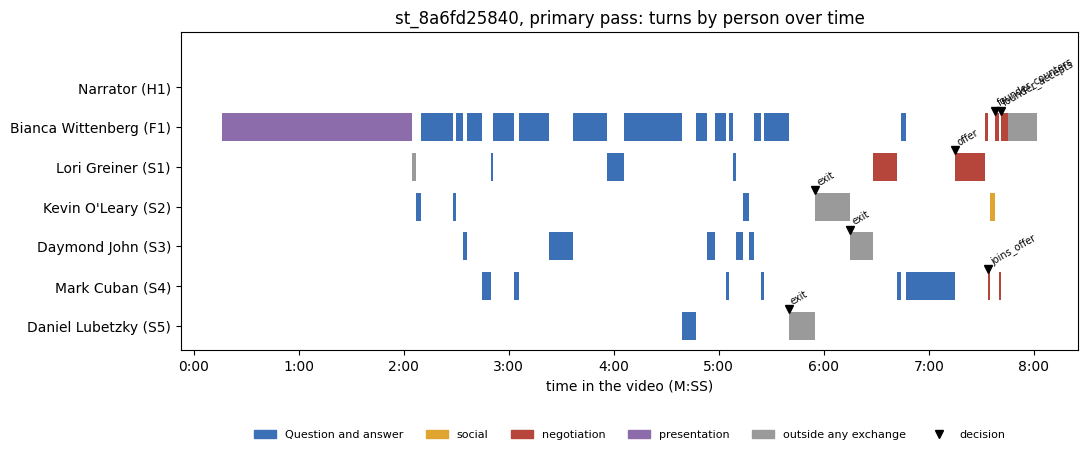

In [21]:
fig = px.timeline_figure(result, f'{VIDEO.name}, {shown_pass} pass: turns by person over time')

### C10. What happens after each answer

One row per answer a founder gives to an investor's question: who asked and what (with the question's
*severity*: 1 asks for information, 2 asks for proof, 3 contests a claim), the answer with its *substance*
(1 low to 5 high) and whether it gave *checkable support*, and then the **next move**: the first investor turn
after the answer in turn order, whatever exchange the model put it in. *Asker's next move* says what the
investor who asked did (accepted, asked again, challenged, said something else), or that another investor
spoke first, or that no investor reacted (none spoke again, or the next one stated or negotiated a decision). *Panel's next move* is the first reaction by any investor, whoever it was.

The next move is worked out from the order of the turns in C5, not coded by the model: founder turns, small
talk and demonstrations are passed over, and a turn that states or negotiates a decision does not count as a
reaction. An answer that responds to two questions has a row for each; an answer to a challenge has none. The
analysis notebook counts these moves over all videos (its section H4).

In [22]:
px.show(px.followups_table(VIDEO, result, inst.books), 'No answer in this pass responds to an investor question.', whole=True)

Asked by,Question,Severity,Question summary,Answered by,Answer,Substance,Checkable support,Answer summary,Asker's next move,Panel's next move,Next investor turn,Next turn summary
Kevin O'Leary (S2),turn 3 at 2:07,3,Kevin asks what a homeowner should do if they have already been instructed to evacuate.,Bianca Wittenberg (F1),turn 4 at 2:10,4,no,"Bianca explains that people should evacuate but can wet the property beforehand, or put out small fires early.",asker asks again,a question,"turn 5 at 2:28: Kevin O'Leary (S2), question",Kevin asks to clarify if she is just selling the hose.
Kevin O'Leary (S2),turn 5 at 2:28,1,Kevin asks to clarify if she is just selling the hose.,Bianca Wittenberg (F1),turn 6 at 2:30,3,no,"Bianca explains she is selling the hose with the adapter, as customers already have the pool pump.",another investor speaks first,a question,"turn 7 at 2:34: Daymond John (S3), question",Daymond asks if the pump shown is a standard pump found in every pool.
Daymond John (S3),turn 7 at 2:34,1,Daymond asks if the pump shown is a standard pump found in every pool.,Bianca Wittenberg (F1),turn 8 at 2:36,4,no,"Bianca confirms the pump is standard, but the adapter requires a one-time installation by a pool professional.",another investor speaks first,a question,"turn 9 at 2:45: Mark Cuban (S4), question",Mark notes that the installation requires proactive effort by hiring a pool guy.
Mark Cuban (S4),turn 9 at 2:45,2,Mark notes that the installation requires proactive effort by hiring a pool guy.,Bianca Wittenberg (F1),turn 11 at 2:51,4,yes,Bianca confirms it is a one-time setup and notes many pools already have open ports.,asker asks again,a question,"turn 12 at 3:03: Mark Cuban (S4), question",Mark asks for the selling price and the manufacturing cost of the unit.
Lori Greiner (S1),turn 10 at 2:50,1,"Lori clarifies that once installed, it is a one-time setup that remains ready.",Bianca Wittenberg (F1),turn 11 at 2:51,4,yes,Bianca confirms it is a one-time setup and notes many pools already have open ports.,another investor speaks first,a question,"turn 12 at 3:03: Mark Cuban (S4), question",Mark asks for the selling price and the manufacturing cost of the unit.
Mark Cuban (S4),turn 12 at 3:03,1,Mark asks for the selling price and the manufacturing cost of the unit.,Bianca Wittenberg (F1),turn 13 at 3:06,4,yes,"Bianca states the 50-foot unit sells for 499 and costs 124, and the 100-foot sells for 599.",another investor speaks first,a question,"turn 14 at 3:23: Daymond John (S3), question","Daymond asks for clarification, noting he thought falling timber was the main issue, not flying embers."
Daymond John (S3),turn 14 at 3:23,1,"Daymond asks for clarification, noting he thought falling timber was the main issue, not flying embers.",Bianca Wittenberg (F1),turn 15 at 3:37,4,yes,Bianca explains that flying embers are a huge problem because they travel far and ignite dry patches or trash.,another investor speaks first,a question,"turn 16 at 3:56: Lori Greiner (S1), question",Lori asks Bianca to share her background and the story about her father inventing the product.
Lori Greiner (S1),turn 16 at 3:56,1,Lori asks Bianca to share her background and the story about her father inventing the product.,Bianca Wittenberg (F1),turn 17 at 4:06,4,yes,Bianca shares that her late father came up with the idea after seeing pool water sit unused during fires.,another investor speaks first,a question,"turn 18 at 4:39: Daniel Lubetzky (S5), question",Daniel asks if professional firemen can use the product to drain pools to fight fires.
Daniel Lubetzky (S5),turn 18 at 4:39,1,Daniel asks if professional firemen can use the product to drain pools to fight fires.,Bianca Wittenberg (F1),turn 19 at 4:47,3,no,"Bianca confirms they can, and the long-term goal is for fire departments to map these accessible pools.",another investor speaks first,a question,"turn 20 at 4:53: Daymond John (S3), question",Daymond asks what her current sales figures are.
Day

## D. Agreement between the two passes

**What this shows.** The model annotated every video twice, independently, with the same prompt. The software
then pairs up the turns, exchanges and decisions of the two passes and counts how often they carry the same
value. *Compared* is how many items could be compared, *Agree* how many carry exactly the same value, *Share
agreeing* their ratio. For ratings on a numbered scale, *Within one point* is the share whose two values differ
by at most one, and *Within one (count)* how many those are. The last column says what one compared item is.
The rows are grouped: outcomes and decisions, venture context, the prepared presentation window (counted in
seconds), turns, the codes of questions and answers, exchanges, and the Stage A ratings, all together and item by item.

**What it does not establish.** This is the model agreeing with itself. High agreement means the instrument is
stable when the same model is asked again; it does **not** mean the codes are correct. Low agreement on a field
means that field should not carry much weight until humans have checked it.

### D1. The selected video

In [23]:
reports = px.agreement_reports(RUN, VIDEO_IDS)
px.show(px.agreement_table(px.agreement_reports(RUN, [VIDEO.name]), inst.books),
        "This video has no comparison of two passes (no replicate pass, or no agreement.json).", whole=True)


Part,Field,Compared,Agree,Share agreeing,Within one (count),Within one point,What is counted
Outcomes and decisions,Whether the pitch got any offer,1,1,1.00,<NA>,,pitches
Outcomes and decisions,Whether each investor ever offered,5,5,1.00,<NA>,,investors
Outcomes and decisions,Decisions found by both passes,7,7,1.00,<NA>,,decisions of the primary pass
Outcomes and decisions,Decisions of the replicate pass also found in the primary,7,7,1.00,<NA>,,decisions of the replicate pass
Outcomes and decisions,Who is part of each offer,1,1,1.00,<NA>,,offers
Venture context,"Venture context (industry, form, customer, team gender)",4,4,1.00,<NA>,,fields
Venture context,Primary industry (primary_industry),1,1,1.00,<NA>,,pitches
Venture context,Product form (product_form),1,1,1.00,<NA>,,pitches
Venture context,Customer type (customer_type),1,1,1.00,<NA>,,pitches
Venture context,Presenting team gender composition (founder_gender),1,1,1.00,<NA>,,pitches


### D2. All videos of the run pooled

The same table with the counts of every video added up before the share is taken, so longer videos weigh more.
The second table is the agreement per turn function: how many turns each pass gave that function, how many
were paired with a turn of the same function in the other pass, and 2 × matched / (primary + replicate). The
third table gives, per video, the figures that are averages rather than counts: how many turns and
exchanges each pass found, how similar the two passes are in who speaks when and in what order, and how much
paired exchanges overlap (1 = identical).

In [24]:
print(f"n videos with two passes compared = {len(reports)} of {len(overview)}")
px.show(px.agreement_table(reports, inst.books), "No video in this run has a second pass to compare with.", whole=True)
px.show(px.function_agreement_table(reports), "")
px.show(px.agreement_extras(reports), "")


n videos with two passes compared = 100 of 100


Part,Field,Compared,Agree,Share agreeing,Within one (count),Within one point,What is counted
Outcomes and decisions,Whether the pitch got any offer,100,100,1.00,<NA>,,pitches
Outcomes and decisions,Whether each investor ever offered,501,494,0.99,<NA>,,investors
Outcomes and decisions,Decisions found by both passes,743,678,0.91,<NA>,,decisions of the primary pass
Outcomes and decisions,Decisions of the replicate pass also found in the primary,739,678,0.92,<NA>,,decisions of the replicate pass
Outcomes and decisions,Who is part of each offer,119,93,0.78,<NA>,,offers
Venture context,"Venture context (industry, form, customer, team gender)",400,378,0.94,<NA>,,fields
Venture context,Primary industry (primary_industry),100,94,0.94,<NA>,,pitches
Venture context,Product form (product_form),100,95,0.95,<NA>,,pitches
Venture context,Customer type (customer_type),100,90,0.90,<NA>,,pitches
Venture context,Presenting team gender composition (founder_gender),100,99,0.99,<NA>,,pitches


,Function,Primary turns,Replicate turns,Matched with the same function,Agreement
0,answer,1707,1689,1444,0.85
1,question,1525,1547,1229,0.80
2,decides,742,738,677,0.91
3,negotiates,615,585,363,0.60
4,social,610,564,248,0.42
5,demonstrates,435,386,230,0.56
6,accepts,413,381,185,0.47
7,presents,371,297,172,0.51
8,challenges,248,221,100,0.43
9,NONE,95,79,17,0.20


,Video,Turns (primary / replicate),Exchanges (primary / replicate),"Who speaks, second by second",Order of turns,Mean overlap of paired exchanges,Prepared window overlap,Median start difference (s)
0,st_026c012f68,89 / 68,10 / 7,0.69,0.70,0.92,0.97,0.0
1,st_02f25e2b0a,46 / 52,9 / 11,0.79,0.77,0.93,1.00,0.0
2,st_03c7703a04,63 / 71,16 / 11,0.78,0.76,0.85,0.98,0.0
3,st_04fd2fd01d,65 / 61,6 / 8,0.85,0.82,0.61,0.72,0.0
4,st_05bb42aa6d,117 / 82,19 / 21,0.36,0.43,0.87,1.00,1.0
...,...,...,...,...,...,...,...,...
95,st_fb39374b09,86 / 84,15 / 13,0.71,0.80,0.77,1.00,1.0
96,st_fb94ba9b86,53 / 52,13 / 12,0.88,0.85,0.89,1.00,0.0
97,st_fd5a8ee737,46 / 42,12 / 5,0.75,0.72,0.93,0.96,1.0
98,st_fe22601532,58 / 66,12 / 14,0.90,0.86,0.90,0.93,0.0


### D3. Where the passes disagree on concepts

Each table counts paired items by the value the primary pass gave (rows) and the value the replicate gave
(columns), pooled over the run. Numbers on the diagonal are agreements; a number off the diagonal shows which
two values get confused with each other.

In [25]:
for what, title in (("PR-CONCEPT", "Question concept"), ("RS-CONCEPT", "Answer concept")):
    print(f"\n{title}: primary pass (rows) by replicate pass (columns), n videos = {len(reports)}")
    px.show(px.confusion_table(reports, what), "  nothing to compare.")


Question concept: primary pass (rows) by replicate pass (columns), n videos = 100


,NONE,assets,competition,customer_acquisition,customer_retention,deal_terms,execution,forecast,go_to_market,liability,market_opportunity,operating_efficiency,other,safety_security,sales,self_promotion,team_capabilities,usage,vision,∅
primary ↓ / replicate →,,,,,,,,,,,,,,,,,,,,
NONE,1,2,0,0,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,0
assets,0,47,1,0,0,2,5,0,0,0,0,3,0,0,0,0,0,1,1,0
competition,0,1,29,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,0,0
customer_acquisition,0,1,0,12,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0
customer_retention,0,1,0,0,7,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
deal_terms,0,1,0,0,0,103,4,1,0,0,0,5,0,0,1,0,2,0,0,0
execution,1,13,0,0,0,8,124,3,5,1,0,4,2,0,9,2,4,11,2,0
forecast,0,0,0,0,0,0,1,26,1,0,0,4,0,0,2,0,0,0,0,0
go_to_market,0,1,0,3,0,1,3,0,74,0,0,0,0,0,11,0,0,0,0,0



Answer concept: primary pass (rows) by replicate pass (columns), n videos = 100


,NONE,assets,competition,customer_acquisition,customer_retention,deal_terms,execution,forecast,go_to_market,liability,market_opportunity,operating_efficiency,other,safety_security,sales,self_promotion,team_capabilities,usage,vision,∅
primary ↓ / replicate →,,,,,,,,,,,,,,,,,,,,
NONE,10,3,0,1,0,0,6,0,2,0,1,1,0,0,1,2,1,1,0,0
assets,1,56,2,0,0,3,5,0,1,0,0,4,0,0,0,0,0,2,1,0
competition,0,2,31,0,0,0,1,0,1,0,1,0,0,0,1,1,0,1,0,0
customer_acquisition,0,0,0,14,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
customer_retention,0,0,0,0,7,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0
deal_terms,1,0,0,0,0,92,3,0,4,0,0,5,1,0,2,1,2,0,2,0
execution,4,10,1,0,0,8,130,3,5,0,1,5,2,0,9,3,5,12,5,0
forecast,0,0,0,0,0,0,0,32,2,0,0,1,0,0,3,0,0,0,0,0
go_to_market,1,2,2,4,0,7,4,0,73,0,0,0,0,0,16,1,0,0,1,0


### D4. Every specific disagreement in the selected video

One row per disagreement the comparison found, in time order, with the clock time in each pass so you can find
the moment in the video. The first table counts them by type. "Turn in one pass only" is the most common: the
two passes often cut the same speech into a different number of turns.

In [26]:
differences = px.video_disagreements(VIDEO)
px.show(differences["What"].value_counts().rename("count").to_frame() if len(differences) else None,
        "No disagreements to list: the comparison flagged none, or this video has no second pass to compare with.")
px.show(differences.drop(columns="Kind"), "", whole=True)

,count
What,
rating differs,13
turn in one pass only,10
responds-to link differs,7
times far apart,3
exchange in one pass only,2
exchange topic differs,1
"same turn, different function",1
"person matched by order, not name",1


What,Primary clock,Replicate clock,About,Detail
responds-to link differs,2:05,—,2,primary [0] vs replicate [] (matched-pair indices)
exchange topic differs,2:07,2:07,1,exchanges 1|1: primary execution vs replicate usage
rating differs,2:07,2:07,PR-CONCEPT,turns 3|3: execution vs usage
rating differs,2:10,2:10,RS-CONCEPT,turns 4|4: execution vs usage
exchange in one pass only,2:28,—,2,substantive exchange shares turns with no free replicate exchange
rating differs,2:28,2:28,PR-CONCEPT,turns 5|5: sales vs execution
rating differs,2:30,2:30,RS-CONCEPT,turns 6|6: sales vs execution
rating differs,2:36,2:36,RS-EVID,turns 8|8: false vs true
rating differs,2:45,2:46,PR-SEV,turns 9|9: 2 vs 3
rating differs,3:37,3:53,PREP-CTX,turns 15|17: 4 vs 1


## E. Human review

**What this shows.** Whether a review sheet (a spreadsheet of sampled items for a human coder to check) has been
written for each video, how many rows a human has reviewed and imported, whether a human-corrected record
exists, and, once sheets have been imported, how often the human gave the same value as the model.

**What it does not establish.** Until rows have been reviewed and imported there is no evidence here about
validity. An exported sheet that nobody has filled in counts for nothing.

In [27]:
display(px.review_status(RUN, VIDEO_IDS))
print(px.review_summary(RUN, VIDEO_IDS) or "No filled review sheet has been imported for this run, so there is no human agreement to report yet.")

,Video,Review sheet,Rows reviewed,Reviewed record,Corrections applied,Human against model
0,st_026c012f68,exported (25 rows),32,no,0,"human = primary on 9/25 sampled rows (0.36), n..."
1,st_02f25e2b0a,not exported,0,no,0,not yet imported
2,st_03c7703a04,not exported,0,no,0,not yet imported
3,st_04fd2fd01d,exported (25 rows),32,no,0,"human = primary on 16/30 sampled rows (0.53), ..."
4,st_05bb42aa6d,not exported,0,no,0,not yet imported
...,...,...,...,...,...,...
95,st_fb39374b09,not exported,0,no,0,not yet imported
96,st_fb94ba9b86,not exported,0,no,0,not yet imported
97,st_fd5a8ee737,not exported,0,no,0,not yet imported
98,st_fe22601532,exported (25 rows),32,no,0,"human = primary on 16/32 sampled rows (0.50), ..."


# Human review summary: full-corpus-100

10 videos with an imported sheet, 320 reviewed rows; 24 structural notes, 0 outcome overrides, 7 first-decision overrides, 27 rows without a definite value.

## Sampled rows (the estimate)

Rows drawn at random, pooled over videos: the share on which the human gives the primary pass's value, with a 95% interval, beside the pass-to-pass figure on the rows that have a replicate value. The first decision agrees when both times map to the same turn of the sheet’s reference pass; unmappable times are excluded and counted separately. Other clock values count as the same within tolerance (a decision time within the agreement settings' tolerance, each edge of the prepared window within two seconds); ordinal fields (rated scales) are compared exactly, and the `within one` column gives the share within one scale point. Rows of one video are not independent, so with at least 5 videos carrying rows of a class the interval resamples whole videos (cluster boo

### How to generate and import a review sheet

The commands below are shown as text; **this notebook does not run them**. Someone who is comfortable with a
terminal runs them from the project folder. Step 1 writes a CSV you can open in any spreadsheet program, with a
page of instructions next to it. Step 2 checks the filled sheet and writes the human-corrected record beside the
model's passes, which are never modified.

In [28]:
print(px.review_commands(RUN, VIDEO.name))

# 1. write a review sheet (a CSV to fill in a spreadsheet) and its instructions
.venv/bin/python scripts/review_panel.py export --run runs/full-corpus-100 --video-ids st_8a6fd25840

# 2. after filling the human_value / resolution columns, check and apply it
.venv/bin/python scripts/review_panel.py import --run runs/full-corpus-100 --sheet runs/full-corpus-100/st_8a6fd25840/review/st_8a6fd25840__review.csv --reviewer YOUR_NAME

# 3. see where every video stands, and the pooled agreement
.venv/bin/python scripts/review_panel.py status --run runs/full-corpus-100
.venv/bin/python scripts/review_panel.py summary --run runs/full-corpus-100


### Human validation

The paper's validation table: how well two blind coders agree with each other and with the model, per field, against thresholds fixed before any sheet was read. It exists only after `review_panel.py summary --paper-table` has been run on the coders' imported sheets (commands in `notebooks/stage_B/README.md`, "Human validation"); until then this section prints one line saying so.

In [29]:
hv = px.human_validation(RUN)
if hv is None:
    print("No validation table yet: run review_panel.py summary --paper-table on this run (see the README).")
else:
    display(hv)

No validation table yet: run review_panel.py summary --paper-table on this run (see the README).


## F. Stage A ranking

**What this shows.** Rating each presentation from 1 to 5 often gives nearly every pitch the same number.
Ranking is a second way to measure the same dimensions (the three Stage A items): the model is shown the prepared presentations of
several videos together, in small batches, and orders them from strongest to weakest on each dimension. The
first table shows the order each batch produced. It lists **every ranked video of the run**, also those not
named in `VIDEO_IDS`, because the ranking was run once over all of them. The second pools all batches into one
score per video (higher = stronger; the scale is relative to the ranked videos of this run), for the videos in
`VIDEO_IDS`. The third asks how consistent the batches are pair by pair: of the pairs of videos ranked together
more than once, what share came out in the same order every time. When every video is ranked in batches of
different clips, hardly any pair meets twice and that table has little or nothing to count.

**How stable is the ranking then?** The last table compares each video with itself: its *standing* in one
batch (1 = strongest of the batch, 0 = weakest) against its standing in another, as a correlation over all
ranked videos (with three batches per video, as in the committed run: the mean over the three pairs of
batches), with a 95% interval from resampling videos and its p-value. Next to it, per dimension: whether the two
annotation passes give the same 1 to 5 rating (Spearman rank correlation), and whether that rating orders the
videos the way the ranking does. The lines printed below the table say how to read the values.

**What it does not establish.** A rank score says where a pitch stands among the ranked pitches of this run
only. It is not comparable across runs, and it is model-coded: a stable ranking is not thereby a correct one.


In [30]:
no_ranking = "This run has no Stage A ranking (there is no ranking/ folder in it), so there is nothing to show here."
px.show(px.ranking_orders(RUN), no_ranking)
px.show(px.ranking_scores(RUN, VIDEO_IDS), "")
px.show(px.ranking_agreement(RUN), "")
stability = px.ranking_stability(RUN)
px.show(stability, "")
print(px.ranking_stability_reading(stability))


,Dimension,Batch,1 (strongest),2,3,4,5
0,expressed_enthusiasm,b01,st_1164b596f8,st_23d21ea284,st_5058b91d09,st_0a7dabb615,st_937fbc68be
1,expressed_enthusiasm,b02,st_f6cfd4372c,st_f9c388f4a8,st_02f25e2b0a,st_248ba1c7b4,st_a6074592e6
2,expressed_enthusiasm,b03,st_e6f74a5072,st_2d69170dfd,st_77524969da,st_9e803962d6,st_ba32f9b9c2
3,expressed_enthusiasm,b04,st_e51a985d9d,st_92462e3ff0,st_03c7703a04,st_c3172f8697,st_edd80b421d
4,expressed_enthusiasm,b05,st_430f6ef097,st_07ecb025ae,st_204899743a,st_52f337ff05,st_aebb7e3764
...,...,...,...,...,...,...,...
175,pitch_positivity,b56,st_66b4676a4f,st_430f6ef097,st_f9c388f4a8,st_675e3b3fd5,st_af8ecff15c
176,pitch_positivity,b57,st_248ba1c7b4,st_f9125ccb14,st_80791baff8,st_ea3eee0ece,st_8a6fd25840
177,pitch_positivity,b58,st_24667730ed,st_e142973a9c,st_d191ae1b7b,st_8642720802,st_7e2ffa37e8
178,pitch_positivity,b59,st_ea1dcf3559,st_db56ed6aad,st_66a79fb6e4,st_c14a7f16bc,st_07ecb025ae


,pitch_positivity,expressed_enthusiasm,interpersonal_warmth
Video,,,
st_026c012f68,0.02,0.83,-0.22
st_02f25e2b0a,1.96,0.29,3.47
st_03c7703a04,-0.21,-0.39,0.26
st_04fd2fd01d,-1.00,-2.33,5.06
st_05bb42aa6d,-3.22,-3.52,-1.57
...,...,...,...
st_fb39374b09,-3.92,-2.43,-3.41
st_fb94ba9b86,0.79,0.62,-0.45
st_fd5a8ee737,-2.03,-2.08,-2.28


,Dimension,Batches,Pairs ranked more than once,Ordered the same way every time,Share consistent
0,pitch_positivity,60,0,0,None
1,expressed_enthusiasm,60,0,0,None
2,interpersonal_warmth,60,0,0,None


,Dimension,Videos ranked in two batches,Batch-to-batch correlation of standing,"95% interval, low","95% interval, high",p-value,Videos rated in both passes,Primary vs replicate rating (Spearman),Videos with a rating and a rank score,Primary rating vs rank score (Spearman),Batches per video
0,expressed_enthusiasm,100,0.59,0.48,0.69,0.0005,100,0.37,100,0.42,3
1,interpersonal_warmth,100,0.51,0.40,0.62,0.0005,100,0.54,100,0.60,3
2,pitch_positivity,100,0.61,0.51,0.71,0.0005,100,0.45,100,0.53,3


Over 100 videos, each ranked in 3 different batches, a video's standing in one batch correlates with its standing in another (mean over the pairs of its batches) between 0.51 (interpersonal_warmth) and 0.61 (pitch_positivity).
How to read a value: 1 would mean a video always lands in the same place whoever it is compared with; 0 that its place in one batch says nothing about its place in another. Around 0.5 is moderate. One batch gives only a coarse standing (a place among a handful of clips, which also depends on which clips happened to be in the batch). The pooled rank score uses all 3 of a video's batches and is steadier than any one: at the mean single-batch correlation here (0.57), a score pooled over 3 batches is expected to correlate about 0.80 with another such score (Spearman-Brown, k r / (1 + (k - 1) r)).
The two rating columns are a different question: do the two annotation passes give the same 1-5 rating, and does the rating order the videos as the ranking does? A low value

## G. Comparison with the earlier (structured) pipeline

**What this shows.** The earlier pipeline annotated the same videos in many small calls and stopped at the
first decision. When a comparison file exists for the run, the first table shows how much more of each video
this run covers (turns, questions and answers after the point where the old pipeline stopped), and the second
how many model calls and tokens each approach used.

**What it does not establish.** Covering more of the video is not the same as coding it better; and the two
pipelines used different codebooks, so their codes are not compared here. The comparison file belongs to the run, not
to `VIDEO_IDS`; the committed run has none, so the section says so.

In [31]:
comparison = px.comparison_tables(RUN)
no_file = "This run has no comparison_vs_structured.json, so there is no comparison to show."
px.show(comparison and comparison["coverage"], no_file, whole=True)
px.show(comparison and comparison["cost"], "", whole=True)

This run has no comparison_vs_structured.json, so there is no comparison to show.



## H. Optional export

With `EXPORT = True` in the configuration cell, the tables above are saved as CSV files (which open in any
spreadsheet program) under `runs/<run>/analysis/explorer/`. Nothing else is written, and annotation files are
never touched. With `EXPORT = False` this cell writes nothing.

In [32]:
if EXPORT:
    out = px.export_tables(RUN, {
        "run_overview": overview, "exchanges": px.exchange_table(result), "turns": px.turn_table(result, inst.books),
        "decisions": px.decisions_table(result), "agreement_selected_video": px.agreement_table(px.agreement_reports(RUN, [VIDEO.name]), inst.books),
        "agreement_pooled": px.agreement_table(reports, inst.books), "disagreements_selected_video": differences,
        "review_status": px.review_status(RUN, VIDEO_IDS), "agreement_by_function_pooled": px.function_agreement_table(reports),
        "stage_a_ranking_agreement": stability,
        "answers_and_next_moves": px.followups_table(VIDEO, result, inst.books)})
    print(f"Saved {len(list(out.glob('*.csv')))} CSV files to {out}")
else:
    print("EXPORT is False: nothing was written.")

EXPORT is False: nothing was written.
